<a href="https://colab.research.google.com/github/Hadeel-93/HW-6/blob/main/HW_6Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# Homework 6 - Problem 2: Breast Cancer Classification
# 2.a Neural Network Development
# 2.b Comparison with Logistic Regression and SVM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
# ------------------------------------------------------------
# 1. Load the Breast Cancer dataset
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

cancer = load_breast_cancer()

X = cancer.data
# Original sklearn labels: 0 = malignant, 1 = benign
# Recode so that 1 = malignant (positive class), 0 = benign
y = (cancer.target == 0).astype(int)

print("Dataset shape:", X.shape)
print("Number of input features:", X.shape[1])
print("Number of malignant cases:", np.sum(y == 1))
print("Number of benign cases:", np.sum(y == 0))

Dataset shape: (569, 30)
Number of input features: 30
Number of malignant cases: 212
Number of benign cases: 357


In [3]:
# ------------------------------------------------------------
# 2. Split into training, validation, and test sets
# ------------------------------------------------------------

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)

print("\nTraining samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Test samples:", X_test.shape[0])


Training samples: 386
Validation samples: 69
Test samples: 114


In [4]:
# ------------------------------------------------------------
# 3. Standardize input features
# Fit the scaler ONLY on training data to prevent data leakage
# ------------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [5]:
# ------------------------------------------------------------
# 4. Build the fully connected neural network
# ------------------------------------------------------------

model = Sequential([
    Input(shape=(30,)),
    Dense(64, activation="relu"),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# ------------------------------------------------------------
# 5. Train the neural network
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

print("\nEpochs completed:", len(history.history["loss"]))

Epoch 1/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.6710 - loss: 0.5811 - val_accuracy: 0.8406 - val_loss: 0.4386
Epoch 2/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8886 - loss: 0.3123 - val_accuracy: 0.9565 - val_loss: 0.2484
Epoch 3/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9508 - loss: 0.1814 - val_accuracy: 0.9565 - val_loss: 0.1643
Epoch 4/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9637 - loss: 0.1253 - val_accuracy: 0.9710 - val_loss: 0.1320
Epoch 5/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9793 - loss: 0.0928 - val_accuracy: 0.9710 - val_loss: 0.1167
Epoch 6/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9715 - loss: 0.0812 - val_accuracy: 0.9710 - val_loss: 0.1108
Epoch 7/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9870 - loss: 0.0635 - val_accuracy: 0.9855 - val_loss: 0.1045
Epoch 8/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9819 - loss: 0.0625 - val_accuracy: 0.

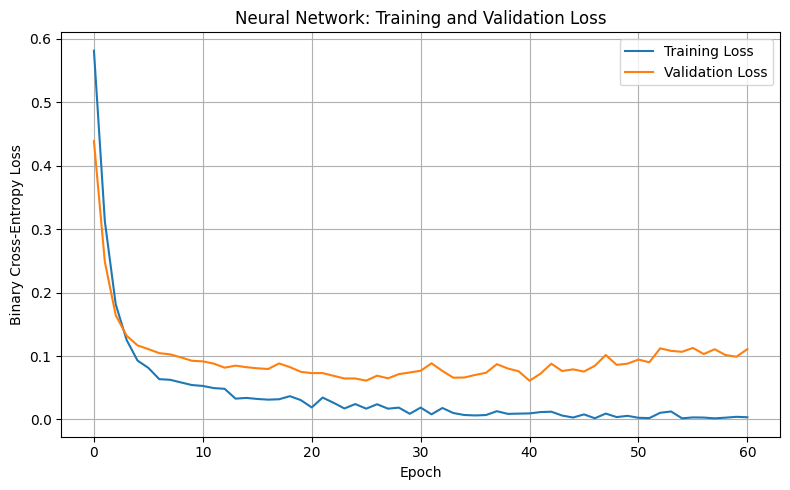

In [7]:
# ------------------------------------------------------------
# 6. Plot training and validation loss
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

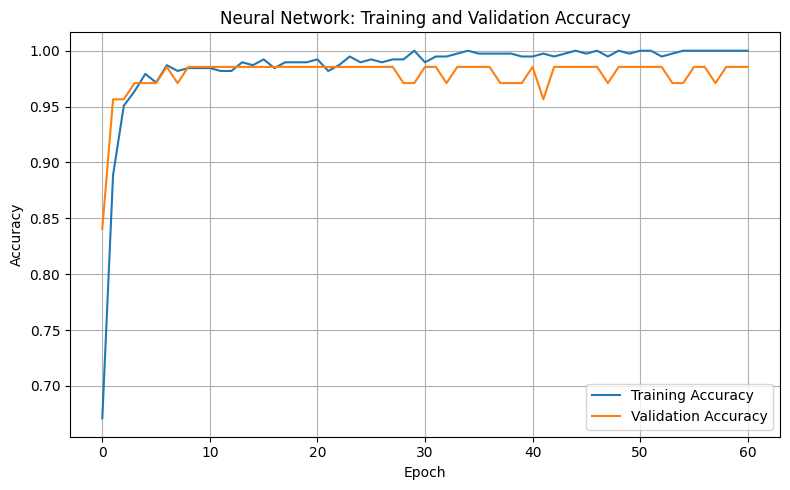

In [8]:
# ------------------------------------------------------------
# 7. Plot training and validation accuracy
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Neural Network: Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# ------------------------------------------------------------
# 8. Evaluate neural network on the test set
# ------------------------------------------------------------

nn_probabilities = model.predict(X_test_scaled, verbose=0).ravel()
nn_predictions = (nn_probabilities >= 0.5).astype(int)


In [10]:
# ------------------------------------------------------------
# 9. Train Logistic Regression
# ------------------------------------------------------------

logistic_model = LogisticRegression(
    solver="liblinear",
    max_iter=5000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled)

In [11]:
# ------------------------------------------------------------
# 10. Train Support Vector Machine (SVM)
# ------------------------------------------------------------

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)


In [12]:
# ------------------------------------------------------------
# 11. Compare test classification performance
# Positive class = malignant
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        )
    }

results = pd.DataFrame({
    "Neural Network": calculate_metrics(y_test, nn_predictions),
    "Logistic Regression": calculate_metrics(y_test, logistic_predictions),
    "SVM (RBF)": calculate_metrics(y_test, svm_predictions)
}).T

print("\nTest Set Performance Comparison:")
print(results.round(4).to_string())


Test Set Performance Comparison:
                     Accuracy  Precision  Recall  F1 Score
Neural Network         0.9737     1.0000  0.9286    0.9630
Logistic Regression    0.9737     0.9756  0.9524    0.9639
SVM (RBF)              0.9737     0.9756  0.9524    0.9639


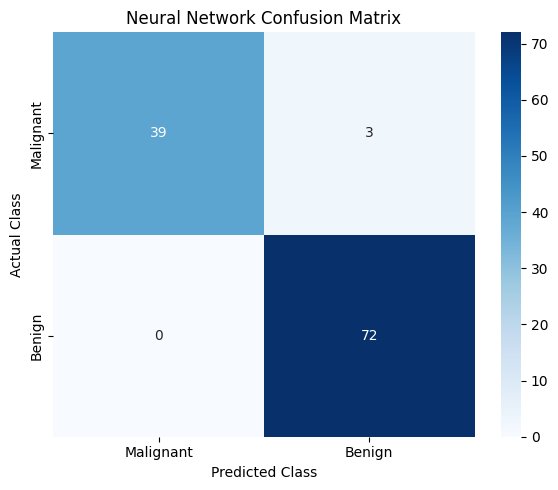

In [13]:
# ------------------------------------------------------------
# 12. Plot neural network confusion matrix
# ------------------------------------------------------------

nn_cm = confusion_matrix(
    y_test, nn_predictions, labels=[1, 0]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    nn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()


In [14]:
# ------------------------------------------------------------
# 13. Print classification reports for all models
# ------------------------------------------------------------

class_names = ["Benign", "Malignant"]

print("\nNEURAL NETWORK CLASSIFICATION REPORT")
print(classification_report(
    y_test, nn_predictions,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test, logistic_predictions,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

print("\nSVM CLASSIFICATION REPORT")
print(classification_report(
    y_test, svm_predictions,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))


NEURAL NETWORK CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0

In [15]:
# ------------------------------------------------------------
# 14. Identify the best model by malignant-class F1 score
# ------------------------------------------------------------

best_model = results["F1 Score"].idxmax()

print("\nBest model by malignant-class F1 score:", best_model)


Best model by malignant-class F1 score: Logistic Regression
